---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [2]:
# ---------- Exercise 1 (A): root finding algorithms ----------
def bisection(f, a, b, tol=1e-6, maxit=1000):
    """Halve the bracket [a,b] until its half-width < tol."""
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("f(a) and f(b) must have opposite signs")
    for i in range(1, maxit + 1):
        c = 0.5 * (a + b)
        fc = f(c)
        if fc == 0 or 0.5 * (b - a) < tol:
            return c, i
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return c, maxit


def secant(f, x0, x1, tol=1e-6, maxit=1000):
    """Newton with the derivative replaced by the slope through the last two points."""
    f0, f1 = f(x0), f(x1)
    for i in range(1, maxit + 1):
        if f1 == f0:                       # flat secant -> cannot continue
            return x1, i
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        if abs(x2 - x1) < tol:
            return x2, i
        x0, f0 = x1, f1
        x1, f1 = x2, f(x2)
    return x1, maxit


def false_position(f, a, b, tol=1e-6, maxit=100000):
    """Regula falsi: secant step, but always keep a sign-changing bracket."""
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("f(a) and f(b) must have opposite signs")
    c_old = None
    for i in range(1, maxit + 1):
        c = b - fb * (b - a) / (fb - fa)
        fc = f(c)
        if fc == 0 or (c_old is not None and abs(c - c_old) < tol):
            return c, i
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
        c_old = c
    return c, maxit


def newton(f, df, x0, tol=1e-6, maxit=1000):
    """Newton-Raphson: x_{n+1} = x_n - f(x_n)/f'(x_n)."""
    x = x0
    for i in range(1, maxit + 1):
        d = df(x)
        if d == 0:
            return x, i
        x_new = x - f(x) / d
        if abs(x_new - x) < tol:
            return x_new, i
        x = x_new
    return x, maxit

In [3]:
# Test on functions with known roots
tests = [
    ("x^2 - 2   (root sqrt(2))", lambda x: x**2 - 2, lambda x: 2*x, 0.0, 2.0, np.sqrt(2)),
    ("cos(x) - x (root 0.739085133215)", lambda x: np.cos(x) - x, lambda x: -np.sin(x) - 1, 0.0, 1.0, 0.7390851332151607),
    ("x^3 - x - 6 (root 2)", lambda x: x**3 - x - 6, lambda x: 3*x**2 - 1, 1.0, 3.0, 2.0),
]
for name, g, dg, a, b, exact in tests:
    print(name)
    for mname, (r, n) in [("bisection", bisection(g, a, b, 1e-12)),
                          ("secant", secant(g, a, b, 1e-12)),
                          ("false position", false_position(g, a, b, 1e-12)),
                          ("Newton", newton(g, dg, b, 1e-12))]:
        print(f"   {mname:15s} root = {r:.12f}  error = {abs(r-exact):.1e}  iterations = {n}")

x^2 - 2   (root sqrt(2))
   bisection       root = 1.414213562372  error = 6.7e-13  iterations = 41
   secant          root = 1.414213562373  error = 2.2e-16  iterations = 8
   false position  root = 1.414213562373  error = 4.7e-14  iterations = 18
   Newton          root = 1.414213562373  error = 2.2e-16  iterations = 6
cos(x) - x (root 0.739085133215)
   bisection       root = 0.739085133216  error = 5.1e-13  iterations = 40
   secant          root = 0.739085133215  error = 0.0e+00  iterations = 6
   false position  root = 0.739085133215  error = 5.6e-15  iterations = 11
   Newton          root = 0.739085133215  error = 0.0e+00  iterations = 5
x^3 - x - 6 (root 2)
   bisection       root = 2.000000000000  error = 0.0e+00  iterations = 1
   secant          root = 2.000000000000  error = 0.0e+00  iterations = 9
   false position  root = 2.000000000000  error = 3.1e-13  iterations = 31
   Newton          root = 2.000000000000  error = 0.0e+00  iterations = 6


**(B)** Note: $f(x)=e^x-1-x-\frac{x^2}{2} = \frac{x^3}{6}+\frac{x^4}{24}+\dots$, i.e. the only root is $x=0$ and it is a **triple root** ($f(0)=f'(0)=f''(0)=0$). This matters a lot for the behaviour below.

Start values: bracket $[a,b]=[-1,2]$ for bisection and false position, $x_0=-1, x_1=2$ for the secant method, and $x_0=2$ (and, for comparison, $x_0=-1$) for Newton. Tolerance on the step size: $10^{-6}$.

In [4]:
f  = lambda x: exp(x) - 1 - x - x**2/2
df = lambda x: exp(x) - 1 - x

a, b, tol = -1.0, 2.0, 1e-6
results = {
    "bisection":          bisection(f, a, b, tol),
    "secant":             secant(f, a, b, tol),
    "false position":     false_position(f, a, b, tol),
    "Newton (x0 = 2)":    newton(f, df, 2.0, tol),
    "Newton (x0 = -1)":   newton(f, df, -1.0, tol),
}
print(f"f(-1) = {f(-1):.4f},  f(2) = {f(2):.4f}  -> sign change, root bracketed\n")
for name, (r, n) in results.items():
    print(f"{name:18s} root = {r: .3e}   iterations = {n}")

f(-1) = -0.1321,  f(2) = 2.3891  -> sign change, root bracketed

bisection          root =  7.629e-06   iterations = 17
secant             root = -6.883e-06   iterations = 43
false position     root = -1.925e-02   iterations = 9575
Newton (x0 = 2)    root =  5.579e-06   iterations = 42
Newton (x0 = -1)   root = -5.561e-06   iterations = 34


**Floating-point limit.** For small $x$ the true value $f(x)\approx x^3/6$ is tiny, but we compute it as a difference of $\mathcal O(1)$ numbers ($e^x$, $1$, $x$, …), so the rounding error is $\sim 10^{-16}$. $f$ is therefore pure noise once $|x|^3/6 \lesssim 10^{-16}$, i.e. $|x|\lesssim 10^{-5}$. No method can locate the root better than $\sim10^{-5}$ with this formula — asking for a smaller tolerance just makes the iteration wander in the noise (or stop early because $f$ rounds to exactly 0). To check that this is the cause, here is the same comparison with $f$ evaluated via its Taylor series near 0 (no cancellation) and a tolerance of $10^{-10}$:

In [5]:
from math import factorial

def f_stable(x):
    if abs(x) < 0.5:
        return sum(x**n / factorial(n) for n in range(3, 20))
    return exp(x) - 1 - x - x**2/2

def df_stable(x):
    if abs(x) < 0.5:
        return sum(x**n / factorial(n) for n in range(2, 20))
    return exp(x) - 1 - x

tol = 1e-10
stable = {
    "bisection":        bisection(f_stable, a, b, tol),
    "secant":           secant(f_stable, a, b, tol),
    "false position":   false_position(f_stable, a, b, tol, maxit=10**6),
    "Newton (x0 = 2)":  newton(f_stable, df_stable, 2.0, tol),
    "Newton (x0 = -1)": newton(f_stable, df_stable, -1.0, tol),
}
for name, (r, n) in stable.items():
    print(f"{name:18s} root = {r: .3e}   iterations = {n}")

bisection          root =  2.910e-11   iterations = 35
secant             root = -2.566e-10   iterations = 79
false position     root = -1.892e-03   iterations = 1000000
Newton (x0 = 2)    root =  1.638e-10   iterations = 58
Newton (x0 = -1)   root = -1.840e-10   iterations = 55


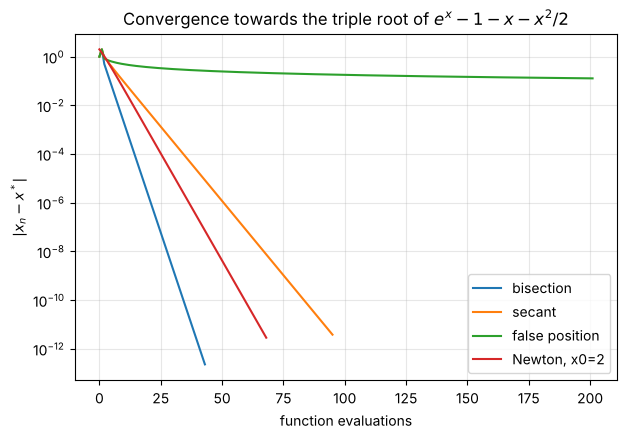

In [6]:
# Convergence history |x_n - 0| for each method (stable f), to see the convergence rates
def history(method, *args, n=200):
    xs = []
    fw = lambda x: (xs.append(x), f_stable(x))[1]
    if method is newton:
        def fw2(x):
            xs.append(x); return f_stable(x)
        newton(fw2, df_stable, *args, tol=1e-12, maxit=n)
    else:
        method(fw, *args, tol=1e-12, maxit=n)
    return np.abs(np.array(xs))

plt.figure(figsize=(7, 4.5))
for name, m, args in [("bisection", bisection, (a, b)), ("secant", secant, (a, b)),
                      ("false position", false_position, (a, b)), ("Newton, x0=2", newton, (2.0,))]:
    h = history(m, *args)
    plt.semilogy(h[h > 0], label=name)
plt.xlabel("function evaluations"); plt.ylabel(r"$|x_n - x^*|$")
plt.title(r"Convergence towards the triple root of $e^x-1-x-x^2/2$")
plt.legend(); plt.grid(alpha=.3); plt.show()

**(C) Discussion**

* **Fastest: bisection** (≈17 iterations to $10^{-6}$, 35 to $10^{-10}$). Its error halves every step regardless of $f$, so it needs $\log_2\!\big((b-a)/\text{tol}\big)$ iterations — it is completely insensitive to the multiplicity of the root.
* **Newton** is normally quadratic, but that requires $f'(x^*)\neq0$. At a root of multiplicity $m$ it degrades to *linear* convergence with ratio $(m-1)/m = 2/3$: each step only removes a third of the error, so it needs ~40–55 iterations here — slower than bisection. (It would recover quadratic convergence with the modified step $x - m\,f/f'$, $m=3$.)
* **Secant** is normally superlinear (order ≈1.62); at the triple root it also becomes linear, with an even worse ratio than Newton, so it is slower still (~40–80 iterations).
* **Slowest: false position** — it essentially fails. Because $f$ is convex on $[0,2]$ and very flat around 0, the secant chord always lands on the same side of the root, so the endpoint $b$ is never updated; only $a$ creeps towards 0 and the step shrinks so slowly that the stopping test fires (or `maxit` is reached) while the estimate is still ~$10^{-2}$–$10^{-3}$ away. This is the classic failure of regula falsi (fix: Illinois/Anderson–Björck modification).
* **Starting points:** Bisection only depends on the bracket width (iterations $\propto \log_2(b-a)$). For Newton, starting at $x_0=2$ or $-1$ changes the iteration count only by a few steps, since the convergence is linear anyway; the starting point would matter much more for a function with several roots or with $f'\approx0$ away from the root. For false position, the asymmetric bracket ($f(2)=2.39 \gg |f(-1)|=0.13$) is exactly what pins one endpoint — a more symmetric bracket helps but does not cure it.
* **Accuracy limit:** with the formula as given, none of the methods can get closer than $|x|\sim10^{-5}$ (cancellation, see above). That is a property of how $f$ is evaluated, not of the root-finders.

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

**(A)** Matrix form $A\mathbf{x}=\mathbf{b}$:
$$A=\begin{pmatrix}5&3\\1&-4\end{pmatrix},\qquad \mathbf{x}=\begin{pmatrix}x_1\\x_2\end{pmatrix},\qquad \mathbf{b}=\begin{pmatrix}15\\-2\end{pmatrix}.$$

In [7]:
import scipy.linalg as la

A = np.array([[5., 3.],
              [1., -4.]])
b = np.array([15., -2.])

# (B) LU decomposition (with partial pivoting): A = P L U
P, L, U = la.lu(A)
print("P =\n", P)
print("L =\n", L)
print("U =\n", U)
print("P @ L @ U == A :", np.allclose(P @ L @ U, A))

# Solve: forward substitution L y = P^T b, back substitution U x = y
lu_piv = la.lu_factor(A)
x = la.lu_solve(lu_piv, b)
print("\nsolution x =", x, "  (exact: 54/23, 25/23 =", 54/23, 25/23, ")")
print("check A @ x =", A @ x, " vs b =", b, "->", np.allclose(A @ x, b))

P =
 [[1. 0.]
 [0. 1.]]
L =
 [[1.  0. ]
 [0.2 1. ]]
U =
 [[ 5.   3. ]
 [ 0.  -4.6]]
P @ L @ U == A : True

solution x = [2.34782609 1.08695652]   (exact: 54/23, 25/23 = 2.347826086956522 1.0869565217391304 )
check A @ x = [15. -2.]  vs b = [15. -2.] -> True


**(C)** The coefficient matrix is the same $A$ with its two rows swapped. Rather than factorising a new matrix, I reorder the equations so they match the row order of $A$ (5x₁+3x₂ = −7 first, x₁−4x₂ = 3 second) — reordering equations doesn't change the solution. Then only the right-hand side changes, $\mathbf b' = (-7,\,3)^T$, and the existing LU factorisation can be reused: only the cheap $\mathcal O(n^2)$ forward/back substitution is redone, not the $\mathcal O(n^3)$ decomposition. (Equivalently: the new matrix is $P_{12}A$, whose LU factorisation is the same as that of $A$ up to the row permutation.)

In [8]:
b2 = np.array([-7., 3.])          # RHS reordered to match the row order of A
x2 = la.lu_solve(lu_piv, b2)       # reuse the factorisation from (B)
print("solution x =", x2, "  (exact: -19/23, -22/23 =", -19/23, -22/23, ")")

A_orig = np.array([[1., -4.], [5., 3.]]); b_orig = np.array([3., -7.])
print("check in original form:", A_orig @ x2, "vs", b_orig, "->", np.allclose(A_orig @ x2, b_orig))

solution x = [-0.82608696 -0.95652174]   (exact: -19/23, -22/23 = -0.8260869565217391 -0.9565217391304348 )
check in original form: [ 3. -7.] vs [ 3. -7.] -> True


## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

In [9]:
# (A) complex grid; an even number of points so z = 0 (where f'(z) = 0) is not on the grid
N = 800
re = np.linspace(-2, 2, N)
im = np.linspace(-2, 2, N)
X, Y = np.meshgrid(re, im)
Z0 = X + 1j * Y

# (C) the three roots of z^3 - 1: the cube roots of unity
roots = np.exp(2j * np.pi * np.arange(3) / 3)     # 1, -1/2 + i sqrt(3)/2, -1/2 - i sqrt(3)/2
print("roots:", np.round(roots, 6), " check f(roots) =", np.abs(roots**3 - 1).max())

# (B) Newton iteration on the whole grid at once, tracking how many points have converged
def newton_fractal(Z, n_iter):
    Z = Z.copy()
    with np.errstate(divide='ignore', invalid='ignore'):
        for _ in range(n_iter):
            Z = Z - (Z**3 - 1) / (3 * Z**2)
    return Z

for n in [5, 10, 20, 30, 50, 100]:
    Zn = newton_fractal(Z0, n)
    dmin = np.abs(Zn[..., None] - roots).min(axis=-1)
    print(f"{n:4d} iterations: fraction within 1e-8 of a root = {np.mean(dmin < 1e-8):.5f}")

roots: [ 1. +0.j       -0.5+0.866025j -0.5-0.866025j]  check f(roots) = 1.5543122344752192e-15


   5 iterations: fraction within 1e-8 of a root = 0.26942


  10 iterations: fraction within 1e-8 of a root = 0.88462


  20 iterations: fraction within 1e-8 of a root = 0.99257


  30 iterations: fraction within 1e-8 of a root = 0.99953


  50 iterations: fraction within 1e-8 of a root = 1.00000


 100 iterations: fraction within 1e-8 of a root = 1.00000


About 30–50 iterations are enough: after that essentially every grid point sits on one of the three roots (the tiny remainder are points right next to the fractal boundary, where the iteration is chaotic and takes longer). I use 50 below.

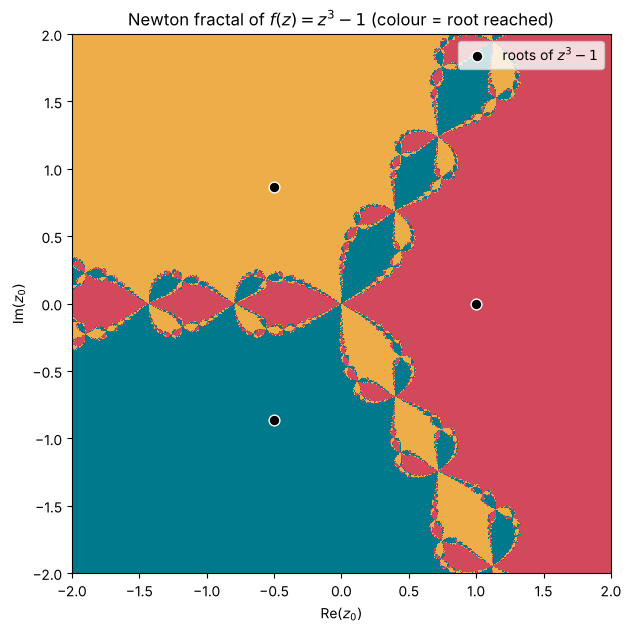

In [10]:
# (C) nearest root for each point after the iteration
Z = newton_fractal(Z0, 50)
dist = np.abs(Z[..., None] - roots)     # shape (N, N, 3)
nearest = np.argmin(dist, axis=-1)      # 0, 1, 2 = index of nearest root

# (D) plot
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#d1495b", "#edae49", "#00798c"])
plt.figure(figsize=(7, 7))
plt.imshow(nearest, extent=[-2, 2, -2, 2], origin="lower", cmap=cmap, interpolation="nearest")
plt.scatter(roots.real, roots.imag, c="k", s=60, marker="o", edgecolors="w", label="roots of $z^3-1$")
plt.xlabel(r"Re$(z_0)$"); plt.ylabel(r"Im$(z_0)$")
plt.title(r"Newton fractal of $f(z)=z^3-1$ (colour = root reached)")
plt.legend(loc="upper right"); plt.show()